In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn sqlalchemy pymysql statsmodels

ITSM Incident Management Using Machine Learning
1. Project Overview

This project aims to improve IT Service Management (ITSM) incident management using Machine Learning techniques.

The project is based on the business case provided for ABC Tech.

2. Problem Statement

ABC Tech receives approximately 22,000–25,000 IT incidents or tickets on average. The company wants to improve incident management and reduce delays in resolving incidents.

3. Project Objectives
Predict high-priority IT tickets.
Forecast future incident volumes.
Automatically classify tickets based on priority and department.
Explore the prediction of Request for Change (RFC) and possible system failures.
4. Dataset Information
Data source: MySQL database specified in the project document.
Database: project_itsm
Approximate records: 46,000.
Time period: 2012, 2013, and 2014.
5. Technologies
Python
Pandas and NumPy
Matplotlib and Seaborn
Scikit-learn
Statsmodels
MySQL

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("ITSM Incident Management Project")
print("--------------------------------")
print("Required libraries imported successfully!")

print("\nChecking available files:")

for dirname, _, filenames in os.walk("/content"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

ITSM Incident Management Project
--------------------------------
Required libraries imported successfully!

Checking available files:
/content/.config/config_sentinel
/content/.config/.last_update_check.json
/content/.config/active_config
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/.last_opt_in_prompt.yaml
/content/.config/.last_survey_prompt.yaml
/content/.config/gce
/content/.config/default_configs.db
/content/.config/configurations/config_default
/content/.config/logs/2026.10.02/13.50.21.555054.log
/content/.config/logs/2026.10.02/13.50.08.874802.log
/content/.config/logs/2026.10.02/13.50.15.366402.log
/content/.config/logs/2026.10.02/13.50.14.261149.log
/content/.config/logs/2026.10.02/13.49.46.128557.log
/content/.config/logs/2026.10.02/13.50.21.004336.log
/content/sample_data/README.md
/content/sample_data/anscombe.json
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv
/content/sample_data/mn

In [3]:
import os

dataset_path = "/content"

files = os.listdir(dataset_path)

print("Available files in Google Colab:\n")

for file in files:
    print(file)

Available files in Google Colab:

.config
sample_data


In [4]:
import getpass
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

db_host = input("Enter MySQL host: ")
db_user = input("Enter MySQL username: ")
db_password = getpass.getpass("Enter MySQL password: ")
db_name = input("Enter database name: ")

try:
    connection_url = (f"mysql+pymysql://{quote_plus(db_user)}:"
        f"{quote_plus(db_password)}@{db_host}/{db_name}")

    engine = create_engine(connection_url)

    with engine.connect() as connection:
        result = connection.execute(text("SELECT 1"))
        print("\nDatabase connection successful!")
        print("Connection test result:", result.scalar())

except Exception as error:
    print("\nDatabase connection failed.")
    print("Error:", str(error)[:300])

Enter MySQL host: 18.136.157.135
Enter MySQL username: dm_team
Enter MySQL password: ··········
Enter database name: project_itsm

Database connection successful!
Connection test result: 1


In [5]:
from sqlalchemy import inspect

inspector = inspect(engine)

tables = inspector.get_table_names()

print("Available Tables in the Database:")
print("----------------------------------")

for table in tables:
    print(table)

Available Tables in the Database:
----------------------------------
dataset_list


In [6]:
from sqlalchemy import inspect

inspector = inspect(engine)
tables = inspector.get_table_names()

print("Total number of tables:", len(tables))
print("\nAvailable Tables:")

for i, table in enumerate(tables, start=1):
    print(f"{i}. {table}")

Total number of tables: 1

Available Tables:
1. dataset_list


In [7]:
from sqlalchemy import inspect

inspector = inspect(engine)
tables = inspector.get_table_names()

if len(tables) == 0:
    print("No tables found in the database.")
else:
    for table in tables:
        print("\n" + "=" * 50)
        print("Table Name:", table)
        print("=" * 50)

        columns = inspector.get_columns(table)

        for column in columns:
            print("Column:", column["name"],"| Data Type:", column["type"])


Table Name: dataset_list
Column: CI_Name | Data Type: VARCHAR(255)
Column: CI_Cat | Data Type: VARCHAR(255)
Column: CI_Subcat | Data Type: VARCHAR(255)
Column: WBS | Data Type: VARCHAR(255)
Column: Incident_ID | Data Type: VARCHAR(255)
Column: Status | Data Type: VARCHAR(255)
Column: Impact | Data Type: VARCHAR(255)
Column: Urgency | Data Type: VARCHAR(255)
Column: Priority | Data Type: VARCHAR(255)
Column: number_cnt | Data Type: VARCHAR(255)
Column: Category | Data Type: VARCHAR(255)
Column: KB_number | Data Type: VARCHAR(255)
Column: Alert_Status | Data Type: VARCHAR(255)
Column: No_of_Reassignments | Data Type: VARCHAR(255)
Column: Open_Time | Data Type: VARCHAR(255)
Column: Reopen_Time | Data Type: VARCHAR(255)
Column: Resolved_Time | Data Type: VARCHAR(255)
Column: Close_Time | Data Type: VARCHAR(255)
Column: Handle_Time_hrs | Data Type: VARCHAR(255)
Column: Closure_Code | Data Type: VARCHAR(255)
Column: No_of_Related_Interactions | Data Type: VARCHAR(255)
Column: Related_Intera

In [8]:
from sqlalchemy import inspect

inspector = inspect(engine)
tables = inspector.get_table_names()

print("Available tables:", tables)

table_name = input("Enter the incident table name from the list above: ").strip()

if table_name not in tables:
    print("Invalid table name. Please check the available tables.")
else:
    from sqlalchemy import MetaData, Table, select

    metadata = MetaData()
    incident_table = Table(table_name,metadata,autoload_with=engine)

    query = select(incident_table).limit(5)

    with engine.connect() as connection:
        sample_data = pd.read_sql(query, connection)

    display(sample_data)

Available tables: ['dataset_list']
Enter the incident table name from the list above: dataset_list


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,...,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,,,
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,,,


In [9]:
import pandas as pd
from sqlalchemy import text

query = text("SELECT * FROM dataset_list LIMIT 10")

with engine.connect() as connection:
    dataset_df = pd.read_sql(query, connection)

print("Dataset List:")
display(dataset_df)

print("\nColumn Names:")
print(dataset_df.columns.tolist())

Dataset List:


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,...,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,,,
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,,,
5,WBA000124,application,Web Based Application,WBS000088,IM0000013,Closed,4,4,4,0.006675648,...,,08-11-2013 13:54,08-11-2013 13:54,"3,38,34,36,944",Other,1,SD0000031,,,
6,WBA000082,application,Web Based Application,WBS000055,IM0000014,Closed,4,4,4,0.19290712,...,,27-12-2013 10:59,27-12-2013 10:59,"3,70,31,91,389",Unknown,1,SD0000033,,,
7,WBA000124,application,Web Based Application,WBS000088,IM0000015,Closed,4,4,4,0.996467545,...,,08-11-2013 14:09,08-11-2013 14:09,"3,29,46,24,167",Other,1,SD0000034,,,
8,WBA000124,application,Web Based Application,WBS000088,IM0000017,Closed,NS,3,NA,0.269573825,...,,08-11-2013 14:02,08-11-2013 14:02,"0,862777778",Other,1,SD0000036,,,
9,WBA000082,application,Web Based Application,WBS000055,IM0000018,Closed,4,4,4,0.306670312,...,,08-11-2013 14:33,08-11-2013 14:35,"3,21,15,26,944",No error - works as designed,1,SD0000037,,,



Column Names:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'WBS', 'Incident_ID', 'Status', 'Impact', 'Urgency', 'Priority', 'number_cnt', 'Category', 'KB_number', 'Alert_Status', 'No_of_Reassignments', 'Open_Time', 'Reopen_Time', 'Resolved_Time', 'Close_Time', 'Handle_Time_hrs', 'Closure_Code', 'No_of_Related_Interactions', 'Related_Interaction', 'No_of_Related_Incidents', 'No_of_Related_Changes', 'Related_Change']


In [10]:
from sqlalchemy import inspect

inspector = inspect(engine)

columns = inspector.get_columns("dataset_list")

print("Dataset List Table Structure")
print("-" * 40)

for column in columns:
    print(f"Column Name: {column['name']}")
    print(f"Data Type: {column['type']}")
    print("-" * 40)

Dataset List Table Structure
----------------------------------------
Column Name: CI_Name
Data Type: VARCHAR(255)
----------------------------------------
Column Name: CI_Cat
Data Type: VARCHAR(255)
----------------------------------------
Column Name: CI_Subcat
Data Type: VARCHAR(255)
----------------------------------------
Column Name: WBS
Data Type: VARCHAR(255)
----------------------------------------
Column Name: Incident_ID
Data Type: VARCHAR(255)
----------------------------------------
Column Name: Status
Data Type: VARCHAR(255)
----------------------------------------
Column Name: Impact
Data Type: VARCHAR(255)
----------------------------------------
Column Name: Urgency
Data Type: VARCHAR(255)
----------------------------------------
Column Name: Priority
Data Type: VARCHAR(255)
----------------------------------------
Column Name: number_cnt
Data Type: VARCHAR(255)
----------------------------------------
Column Name: Category
Data Type: VARCHAR(255)
---------------------

In [11]:
from sqlalchemy import text
import pandas as pd

with engine.connect() as connection:

    # Count the records
    count_query = text("SELECT COUNT(*) FROM dataset_list")
    total_records = connection.execute(count_query).scalar()

    print("Total records in dataset_list:", total_records)

    # Display available records
    data_query = text("SELECT * FROM dataset_list LIMIT 10")
    dataset_df = pd.read_sql(data_query, connection)

print("\nDataset Details:")
display(dataset_df)

Total records in dataset_list: 46606

Dataset Details:


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,...,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,,,
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,,,
5,WBA000124,application,Web Based Application,WBS000088,IM0000013,Closed,4,4,4,0.006675648,...,,08-11-2013 13:54,08-11-2013 13:54,"3,38,34,36,944",Other,1,SD0000031,,,
6,WBA000082,application,Web Based Application,WBS000055,IM0000014,Closed,4,4,4,0.19290712,...,,27-12-2013 10:59,27-12-2013 10:59,"3,70,31,91,389",Unknown,1,SD0000033,,,
7,WBA000124,application,Web Based Application,WBS000088,IM0000015,Closed,4,4,4,0.996467545,...,,08-11-2013 14:09,08-11-2013 14:09,"3,29,46,24,167",Other,1,SD0000034,,,
8,WBA000124,application,Web Based Application,WBS000088,IM0000017,Closed,NS,3,NA,0.269573825,...,,08-11-2013 14:02,08-11-2013 14:02,"0,862777778",Other,1,SD0000036,,,
9,WBA000082,application,Web Based Application,WBS000055,IM0000018,Closed,4,4,4,0.306670312,...,,08-11-2013 14:33,08-11-2013 14:35,"3,21,15,26,944",No error - works as designed,1,SD0000037,,,


In [12]:
from sqlalchemy import text
import pandas as pd

with engine.connect() as connection:
    query = text("SELECT * FROM dataset_list LIMIT 20")
    dataset_df = pd.read_sql(query, connection)

print("Dataset List Information")
print("-" * 40)

print("Number of rows displayed:", len(dataset_df))
print("Available columns:", dataset_df.columns.tolist())

display(dataset_df)

Dataset List Information
----------------------------------------
Number of rows displayed: 20
Available columns: ['CI_Name', 'CI_Cat', 'CI_Subcat', 'WBS', 'Incident_ID', 'Status', 'Impact', 'Urgency', 'Priority', 'number_cnt', 'Category', 'KB_number', 'Alert_Status', 'No_of_Reassignments', 'Open_Time', 'Reopen_Time', 'Resolved_Time', 'Close_Time', 'Handle_Time_hrs', 'Closure_Code', 'No_of_Related_Interactions', 'Related_Interaction', 'No_of_Related_Incidents', 'No_of_Related_Changes', 'Related_Change']


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,...,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,,,
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,,,
5,WBA000124,application,Web Based Application,WBS000088,IM0000013,Closed,4,4,4,0.006675648,...,,08-11-2013 13:54,08-11-2013 13:54,"3,38,34,36,944",Other,1,SD0000031,,,
6,WBA000082,application,Web Based Application,WBS000055,IM0000014,Closed,4,4,4,0.19290712,...,,27-12-2013 10:59,27-12-2013 10:59,"3,70,31,91,389",Unknown,1,SD0000033,,,
7,WBA000124,application,Web Based Application,WBS000088,IM0000015,Closed,4,4,4,0.996467545,...,,08-11-2013 14:09,08-11-2013 14:09,"3,29,46,24,167",Other,1,SD0000034,,,
8,WBA000124,application,Web Based Application,WBS000088,IM0000017,Closed,NS,3,NA,0.269573825,...,,08-11-2013 14:02,08-11-2013 14:02,"0,862777778",Other,1,SD0000036,,,
9,WBA000082,application,Web Based Application,WBS000055,IM0000018,Closed,4,4,4,0.306670312,...,,08-11-2013 14:33,08-11-2013 14:35,"3,21,15,26,944",No error - works as designed,1,SD0000037,,,


In [13]:
import pandas as pd
from sqlalchemy import text

# Load a sample of incident records
query = text("SELECT * FROM dataset_list LIMIT 1000")

with engine.connect() as connection:
    df = pd.read_sql(query, connection)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
missing_values = df.isnull().sum()
display(missing_values[missing_values > 0])

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1000, 25)

First 5 Records:


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,,
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,,
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NA,0.517551335,...,,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,,,
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,,,
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,,,



Column Names:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'WBS', 'Incident_ID', 'Status', 'Impact', 'Urgency', 'Priority', 'number_cnt', 'Category', 'KB_number', 'Alert_Status', 'No_of_Reassignments', 'Open_Time', 'Reopen_Time', 'Resolved_Time', 'Close_Time', 'Handle_Time_hrs', 'Closure_Code', 'No_of_Related_Interactions', 'Related_Interaction', 'No_of_Related_Incidents', 'No_of_Related_Changes', 'Related_Change']

Missing Values:


,0



Data Types:
CI_Name                       object
CI_Cat                        object
CI_Subcat                     object
WBS                           object
Incident_ID                   object
Status                        object
Impact                        object
Urgency                       object
Priority                      object
number_cnt                    object
Category                      object
KB_number                     object
Alert_Status                  object
No_of_Reassignments           object
Open_Time                     object
Reopen_Time                   object
Resolved_Time                 object
Close_Time                    object
Handle_Time_hrs               object
Closure_Code                  object
No_of_Related_Interactions    object
Related_Interaction           object
No_of_Related_Incidents       object
No_of_Related_Changes         object
Related_Change                object
dtype: object


Priority Value Counts:
Priority
4     466
5     412
3      89
NA     32
2       1
Name: count, dtype: int64


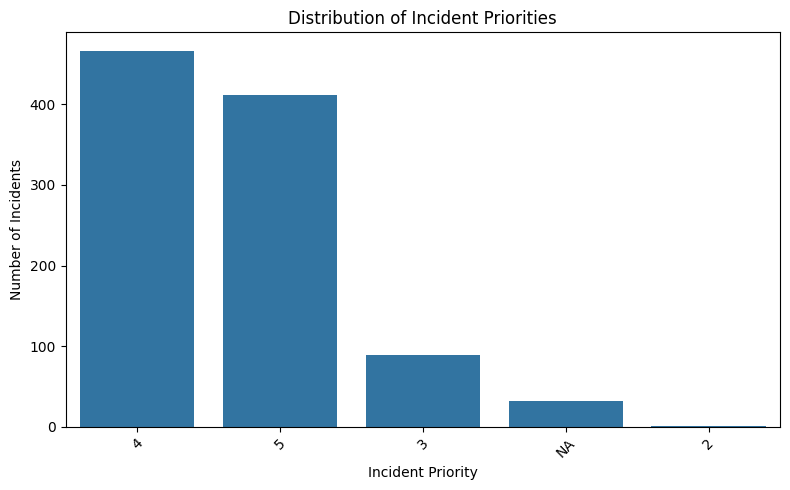

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Priority Value Counts:")
print(df["Priority"].value_counts(dropna=False))

plt.figure(figsize=(8, 5))

sns.countplot(data=df,x="Priority",order=df["Priority"].value_counts().index)

plt.title("Distribution of Incident Priorities")
plt.xlabel("Incident Priority")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Incident Status Distribution:
Status
Closed    1000
Name: count, dtype: int64


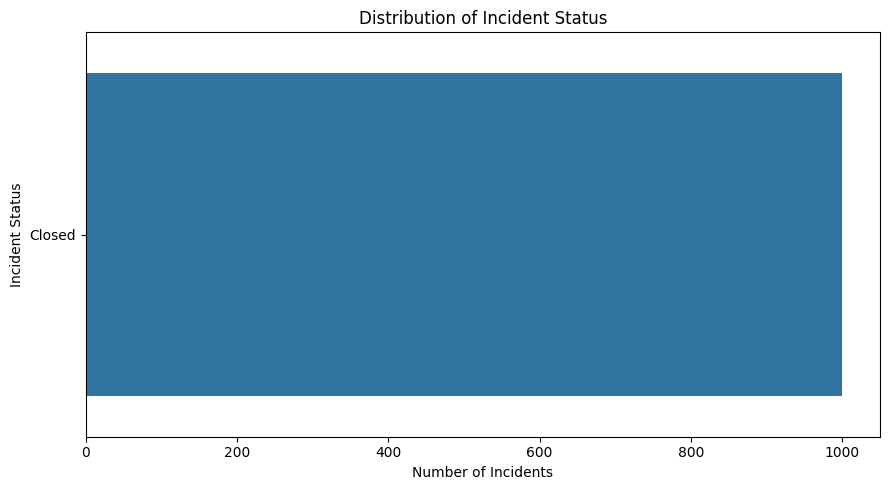

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count incidents by status
status_counts = df["Status"].value_counts(dropna=False)

print("Incident Status Distribution:")
print(status_counts)

# Visualize incident status
plt.figure(figsize=(9, 5))

sns.countplot(data=df,y="Status",order=df["Status"].value_counts().index)

plt.title("Distribution of Incident Status")
plt.xlabel("Number of Incidents")
plt.ylabel("Incident Status")
plt.tight_layout()
plt.show()

Incident Category Distribution:
Category
incident                   779
request for information    221
Name: count, dtype: int64


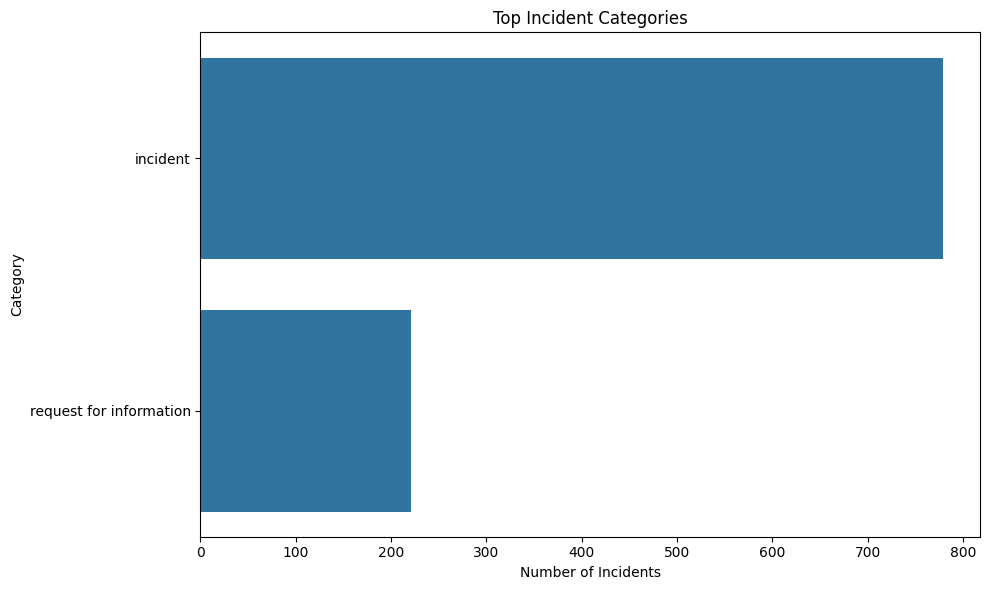

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count incident categories
category_counts = df["Category"].value_counts(dropna=False)

print("Incident Category Distribution:")
print(category_counts)

# Visualize top 15 categories
top_categories = df["Category"].value_counts().head(15)

plt.figure(figsize=(10, 6))

sns.barplot(x=top_categories.values,y=top_categories.index)

plt.title("Top Incident Categories")
plt.xlabel("Number of Incidents")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (missing_count / len(df)) * 100

# Create summary table
missing_summary = pd.DataFrame({"Missing Values": missing_count,"Missing Percentage": missing_percentage.round(2)})

# Show columns with missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0].sort_values(by="Missing Percentage",ascending=False)

print("Missing Values Summary:")

if missing_summary.empty:
    print("No missing values found in this sample.")
else:
    display(missing_summary)

# Visualize missing values
if not missing_summary.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(data=missing_summary.reset_index(),x="Missing Percentage",y="index")

    plt.title("Missing Values by Column")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column Name")
    plt.tight_layout()
    plt.show()

Missing Values Summary:
No missing values found in this sample.


In [18]:
import pandas as pd
import numpy as np

# Create a separate copy for cleaning
df_clean = df.copy()

# Replace common missing-value indicators
missing_indicators = ["", "NA", "N/A", "NULL", "None"]

df_clean = df_clean.replace(missing_indicators,np.nan)

# Remove leading and trailing spaces from text columns
for column in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[column] = df_clean[column].apply(lambda value: value.strip() if isinstance(value, str) else value)

# Display missing-value summary
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing Values After Cleaning:")

missing_summary = df_clean.isnull().sum()
missing_summary = missing_summary[missing_summary > 0]

if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary.sort_values(ascending=False))

print("\nCleaned Data Preview:")
display(df_clean.head())

Original dataset shape: (1000, 25)
Cleaned dataset shape: (1000, 25)

Missing Values After Cleaning:


,0
No_of_Related_Changes,972
Related_Change,972
No_of_Related_Incidents,956
Reopen_Time,818
Priority,32
Resolved_Time,28
CI_Cat,4
CI_Subcat,4
No_of_Related_Interactions,1



Cleaned Data Preview:


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4,0.601292279,...,NaN,04-11-2013 13:50,04-11-2013 13:51,"3,87,16,91,111",Other,1,SD0000007,2,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3,0.415049969,...,02-12-2013 12:31,02-12-2013 12:36,02-12-2013 12:36,"4,35,47,86,389",Software,1,SD0000011,1,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551335,...,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4,0.642927218,...,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4,0.345258343,...,NaN,08-11-2013 13:55,08-11-2013 13:55,"3,38,39,03,333",Other,1,SD0000029,NaN,NaN,NaN


In [19]:
# Check completely duplicated rows
duplicate_rows = df_clean.duplicated().sum()

print("Total duplicate rows:", duplicate_rows)

# Check duplicate Incident IDs
duplicate_incidents = df_clean["Incident_ID"].duplicated().sum()

print("Total duplicate Incident IDs:", duplicate_incidents)

# Display duplicate incident records
df_clean[df_clean["Incident_ID"].duplicated(keep=False)].head(10)

Total duplicate rows: 0
Total duplicate Incident IDs: 0


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change


Incident Priority Distribution:
Priority
4      466
5      412
3       89
NaN     32
2        1
Name: count, dtype: int64


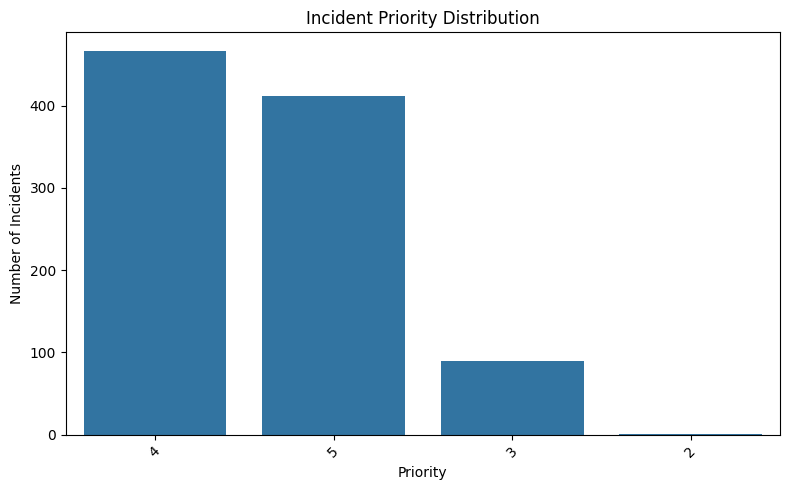

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count incidents by priority
priority_counts = df_clean["Priority"].value_counts(dropna=False)

print("Incident Priority Distribution:")
print(priority_counts)

# Plot priority distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean,x="Priority",order=df_clean["Priority"].value_counts().index)

plt.title("Incident Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Impact Distribution:
Impact
4     470
5     414
3      83
NS     32
2       1
Name: count, dtype: int64

Urgency Distribution:
Urgency
4    466
5    421
3    111
2      2
Name: count, dtype: int64


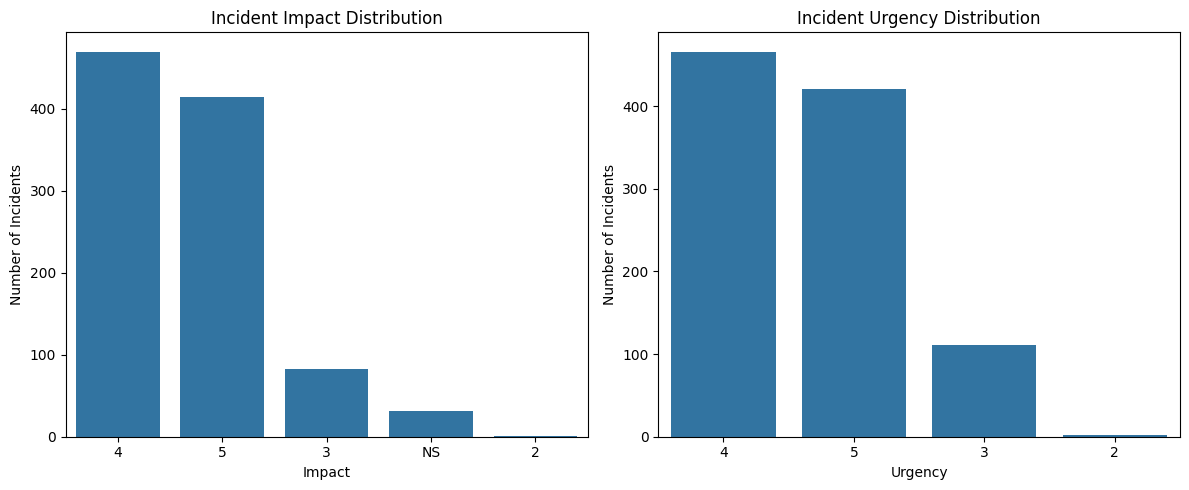

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display Impact distribution
print("Impact Distribution:")
print(df_clean["Impact"].value_counts(dropna=False))

# Display Urgency distribution
print("\nUrgency Distribution:")
print(df_clean["Urgency"].value_counts(dropna=False))

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df_clean,x="Impact",order=df_clean["Impact"].value_counts().index,ax=axes[0])
axes[0].set_title("Incident Impact Distribution")
axes[0].set_xlabel("Impact")
axes[0].set_ylabel("Number of Incidents")

sns.countplot(data=df_clean,x="Urgency",order=df_clean["Urgency"].value_counts().index,ax=axes[1])
axes[1].set_title("Incident Urgency Distribution")
axes[1].set_xlabel("Urgency")
axes[1].set_ylabel("Number of Incidents")

plt.tight_layout()
plt.show()

Incident Status Distribution:
Status
Closed    1000
Name: count, dtype: int64


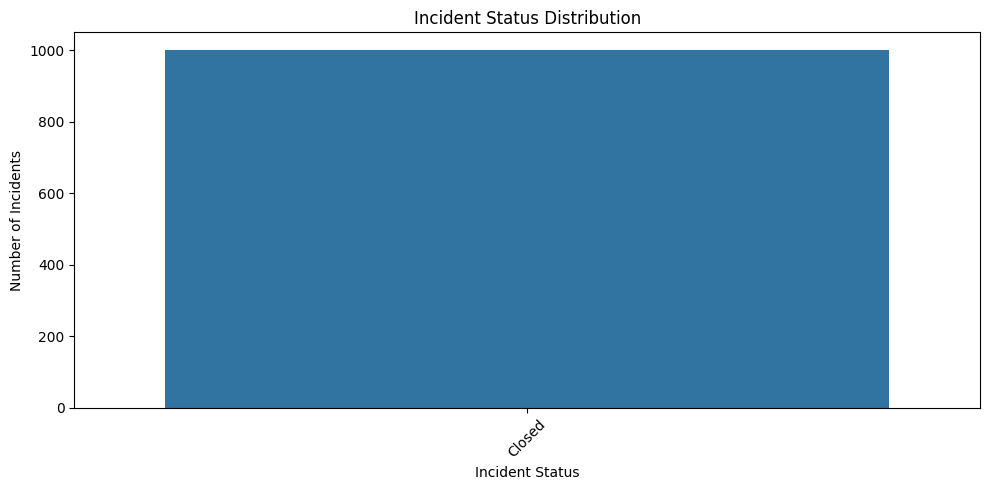

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count incidents by status
status_counts = df_clean["Status"].value_counts(dropna=False)

print("Incident Status Distribution:")
print(status_counts)

# Plot status distribution
plt.figure(figsize=(10, 5))

sns.countplot(data=df_clean,x="Status",order=df_clean["Status"].value_counts().index)

plt.title("Incident Status Distribution")
plt.xlabel("Incident Status")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Incident Category Distribution:
Category
incident                   779
request for information    221
Name: count, dtype: int64


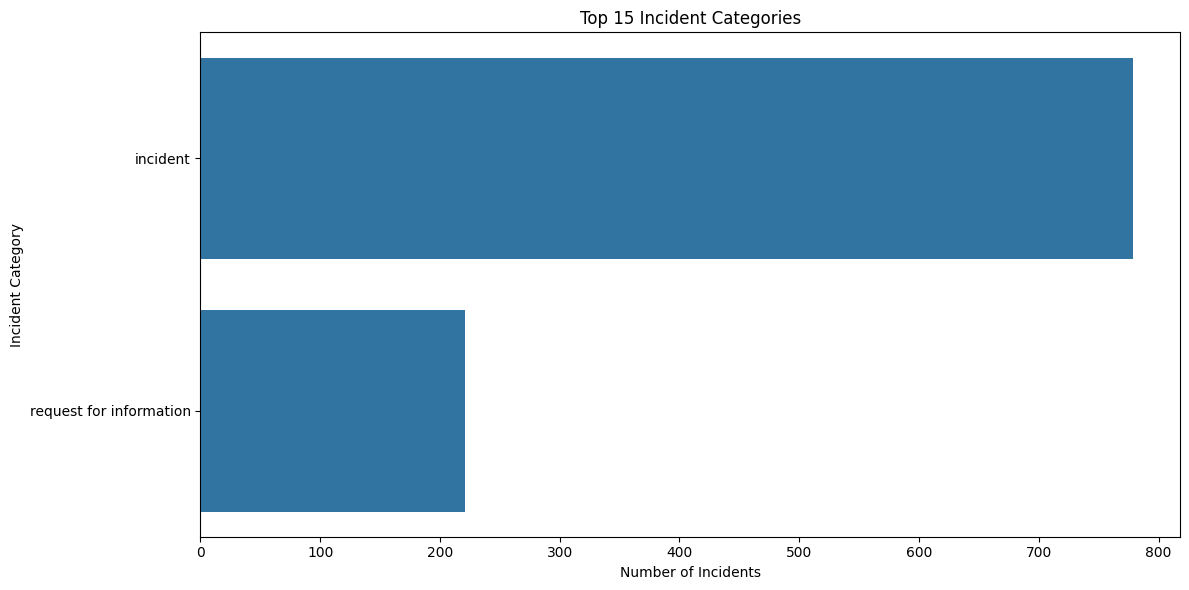

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count incidents by category
category_counts = df_clean["Category"].value_counts(dropna=False)

print("Incident Category Distribution:")
print(category_counts.head(15))

# Plot top 15 categories
top_categories = df_clean["Category"].value_counts().head(15)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_categories.values,y=top_categories.index)

plt.title("Top 15 Incident Categories")
plt.xlabel("Number of Incidents")
plt.ylabel("Incident Category")
plt.tight_layout()
plt.show()

Missing Values Summary:
                            Missing Values  Missing Percentage
No_of_Related_Changes                  972                97.2
Related_Change                         972                97.2
No_of_Related_Incidents                956                95.6
Reopen_Time                            818                81.8
Priority                                32                 3.2
Resolved_Time                           28                 2.8
CI_Cat                                   4                 0.4
CI_Subcat                                4                 0.4
No_of_Related_Interactions               1                 0.1


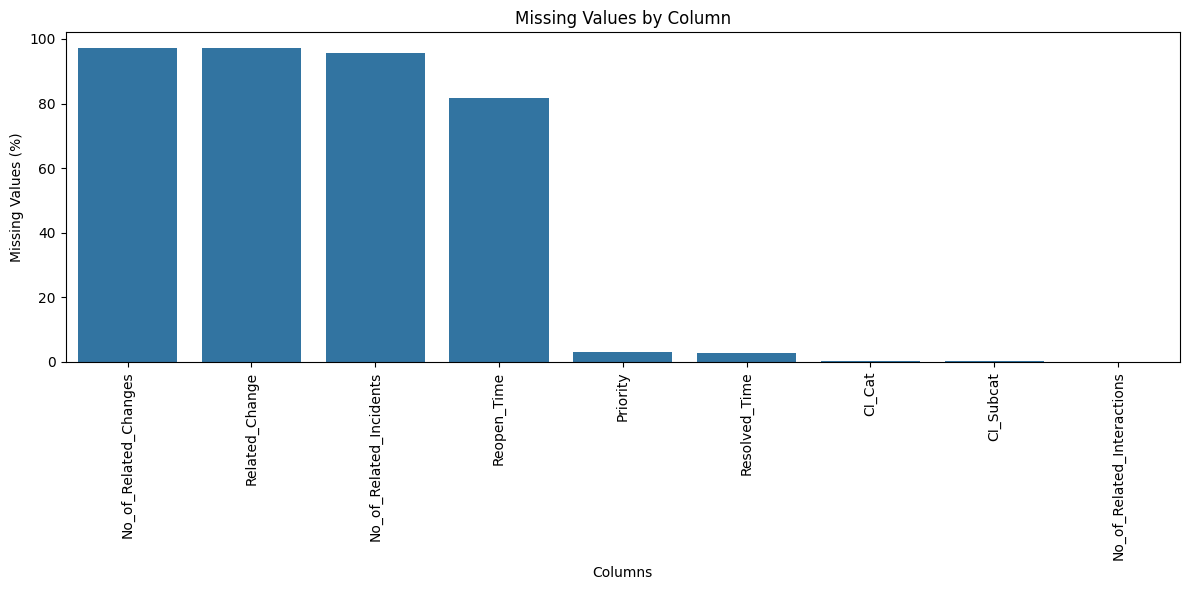

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate missing values
missing_values = df_clean.isnull().sum()

# Calculate missing percentage
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

# Create summary table
missing_summary = pd.DataFrame({"Missing Values": missing_values,"Missing Percentage": missing_percentage})

# Show columns with missing values
missing_summary = missing_summary[missing_summary["Missing Values"] > 0].sort_values(by="Missing Percentage",ascending=False)

print("Missing Values Summary:")
print(missing_summary)

# Plot missing values
if not missing_summary.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(x=missing_summary.index,y=missing_summary["Missing Percentage"])

    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in df_clean.")

In [25]:
import pandas as pd

# Display date and time columns
date_columns = ["Open_Time","Reopen_Time","Resolved_Time","Close_Time"]

print("Incident Date and Time Summary")

for col in date_columns:
    if col in df_clean.columns:
        print(f"\n{col}")
        print("Missing values:", df_clean[col].isnull().sum())
        print("Sample values:")
        print(df_clean[col].head(5))

# Convert date columns into datetime format
for col in date_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_datetime(df_clean[col],errors="coerce")

print("\nUpdated Data Types:")
print(df_clean[date_columns].dtypes)

Incident Date and Time Summary

Open_Time
Missing values: 0
Sample values:
0    05-02-2012 13:32
1    12-03-2012 15:44
2    29-03-2012 12:36
3    17-07-2012 11:49
4    10-08-2012 11:01
Name: Open_Time, dtype: object

Reopen_Time
Missing values: 818
Sample values:
0                 NaN
1    02-12-2013 12:31
2                 NaN
3                 NaN
4                 NaN
Name: Reopen_Time, dtype: object

Resolved_Time
Missing values: 28
Sample values:
0    04-11-2013 13:50
1    02-12-2013 12:36
2    13-01-2014 15:12
3    14-11-2013 09:31
4    08-11-2013 13:55
Name: Resolved_Time, dtype: object

Close_Time
Missing values: 0
Sample values:
0    04-11-2013 13:51
1    02-12-2013 12:36
2    13-01-2014 15:13
3    14-11-2013 09:31
4    08-11-2013 13:55
Name: Close_Time, dtype: object

Updated Data Types:
Open_Time        datetime64[ns]
Reopen_Time      datetime64[ns]
Resolved_Time    datetime64[ns]
Close_Time       datetime64[ns]
dtype: object


Monthly Incident Counts:
Year_Month
2012-01     1
2012-02     1
2012-03     1
2012-05     2
2012-07     1
2012-10     3
2012-12     1
2013-01     6
2013-02    13
2013-03    13
2013-04    18
2013-05    18
2013-06    17
2013-07    12
2013-08    11
2013-09    16
2013-10    28
2013-11    37
2013-12    33
dtype: int64


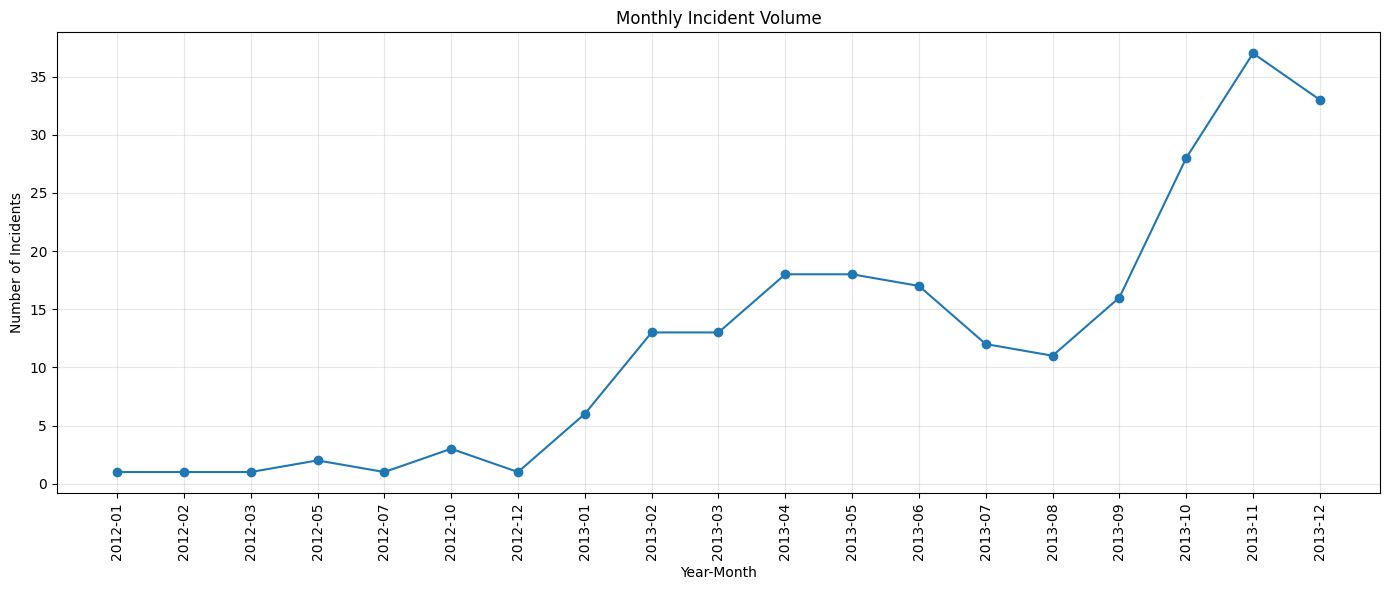

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a separate dataframe for time analysis
time_df = df_clean.copy()

# Ensure Open_Time is in datetime format
time_df["Open_Time"] = pd.to_datetime(time_df["Open_Time"],errors="coerce")

# Remove records without a valid opening date
time_df = time_df.dropna(subset=["Open_Time"])

# Extract year and month
time_df["Year_Month"] = (time_df["Open_Time"].dt.to_period("M").astype(str))

# Count incidents opened each month
monthly_incidents = (time_df.groupby("Year_Month").size().sort_index())

print("Monthly Incident Counts:")
print(monthly_incidents)

# Plot monthly incident volume
plt.figure(figsize=(14, 6))

plt.plot(monthly_incidents.index,monthly_incidents.values,marker="o")

plt.title("Monthly Incident Volume")
plt.xlabel("Year-Month")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Resolution Time Summary:
count      136.000000
mean       712.115564
std       4910.349162
min      -7998.200000
25%      -2157.895833
50%        117.975000
75%       3694.350000
max      18765.433333
Name: Resolution_Time_Hours, dtype: float64

Missing resolution times: 864


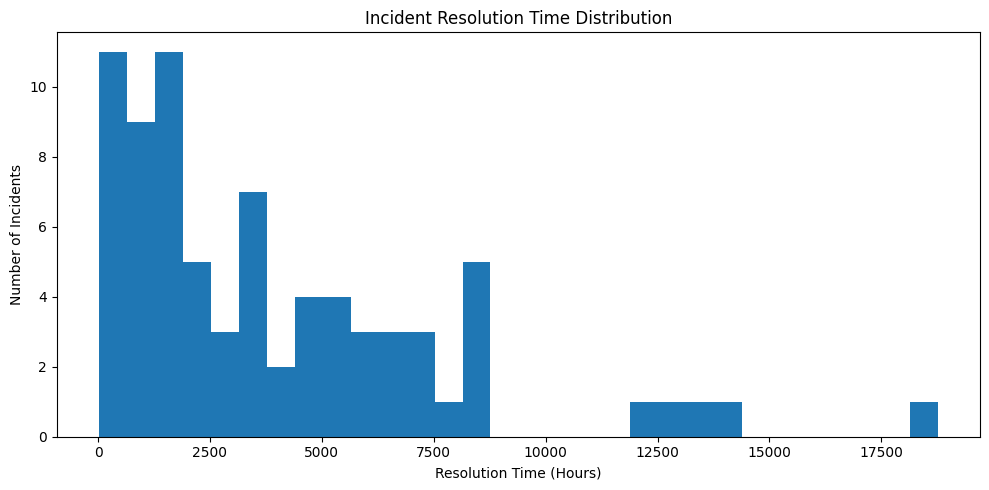

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a separate dataframe
resolution_df = df_clean.copy()

# Convert timestamps to datetime
resolution_df["Open_Time"] = pd.to_datetime(resolution_df["Open_Time"], errors="coerce")

resolution_df["Resolved_Time"] = pd.to_datetime(resolution_df["Resolved_Time"], errors="coerce")

# Calculate resolution time in hours
resolution_df["Resolution_Time_Hours"] = (resolution_df["Resolved_Time"] -resolution_df["Open_Time"]).dt.total_seconds() / 3600

# Display summary
print("Resolution Time Summary:")
print(resolution_df["Resolution_Time_Hours"].describe())

# Count records with missing resolution time
print("\nMissing resolution times:",resolution_df["Resolution_Time_Hours"].isna().sum())

# Keep valid, non-negative resolution times for plotting
valid_resolution = resolution_df.loc[resolution_df["Resolution_Time_Hours"].notna()& (resolution_df["Resolution_Time_Hours"] >= 0),"Resolution_Time_Hours"]

if not valid_resolution.empty:
    plt.figure(figsize=(10, 5))
    plt.hist(valid_resolution, bins=30)
    plt.title("Incident Resolution Time Distribution")
    plt.xlabel("Resolution Time (Hours)")
    plt.ylabel("Number of Incidents")
    plt.tight_layout()
    plt.show()
else:
    print("No valid resolution times available for plotting.")

Reassignment Summary:
count    1000.000000
mean        4.391000
std         5.352267
min         0.000000
25%         1.000000
50%         3.000000
75%         6.000000
max        46.000000
Name: No_of_Reassignments, dtype: float64

Reassignment Counts:
No_of_Reassignments
0     166
1     126
2     188
3      80
4     118
5      58
6      65
7      38
8      28
9      17
10     20
11     11
12     12
13     18
14      9
15      7
16      4
17      6
18      3
19      3
Name: count, dtype: int64


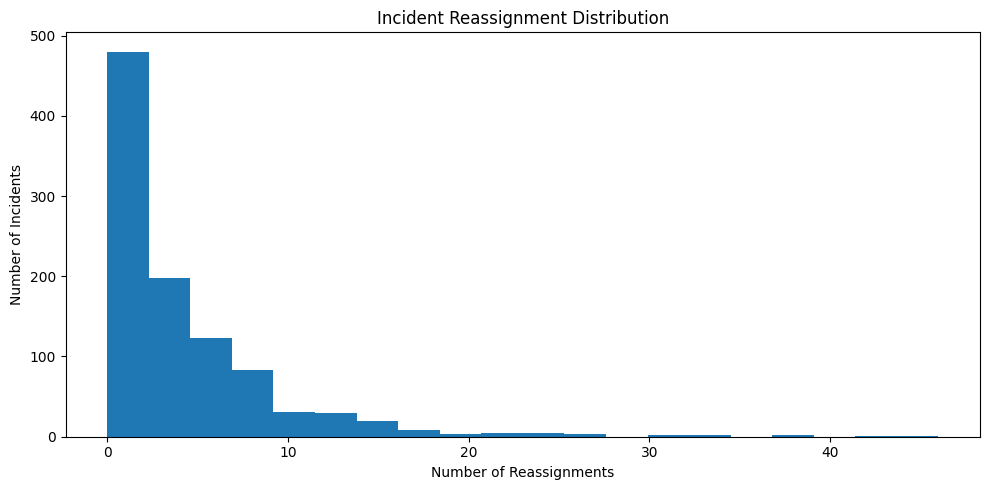

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a separate dataframe
reassignment_df = df_clean.copy()

# Convert reassignment count to numeric
reassignment_df["No_of_Reassignments"] = pd.to_numeric(reassignment_df["No_of_Reassignments"],errors="coerce")

# Display summary statistics
print("Reassignment Summary:")
print(reassignment_df["No_of_Reassignments"].describe())

# Count reassignment values
print("\nReassignment Counts:")
print(reassignment_df["No_of_Reassignments"].value_counts().sort_index().head(20))

# Plot reassignment distribution
valid_reassignments = reassignment_df[reassignment_df["No_of_Reassignments"].notna()& (reassignment_df["No_of_Reassignments"] >= 0)]

if not valid_reassignments.empty:
    plt.figure(figsize=(10, 5))

    plt.hist(valid_reassignments["No_of_Reassignments"],bins=20)

    plt.title("Incident Reassignment Distribution")
    plt.xlabel("Number of Reassignments")
    plt.ylabel("Number of Incidents")
    plt.tight_layout()
    plt.show()
else:
    print("No valid reassignment values found.")

Incident Handling Time Summary:
count    1.000000e+03
mean     3.496873e+09
std      2.727462e+09
min      1.000000e+00
25%      1.305118e+09
50%      2.878472e+09
75%      5.349181e+09
max      9.978056e+09
Name: Handle_Time_hrs, dtype: float64

Missing handling time values: 0


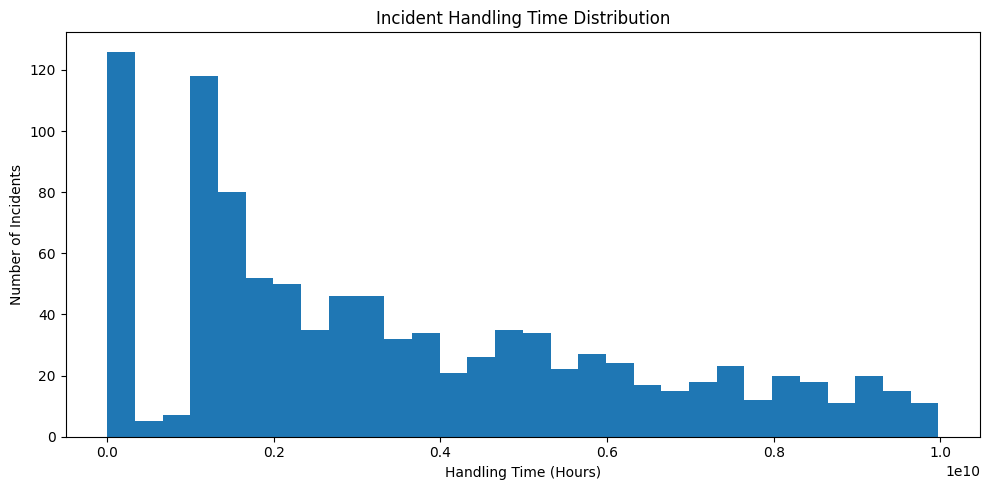

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a separate dataframe
handling_df = df_clean.copy()

# Convert handling time to numeric
handling_df["Handle_Time_hrs"] = pd.to_numeric(handling_df["Handle_Time_hrs"].astype(str).str.replace(",", "", regex=False),errors="coerce")

# Display handling time summary
print("Incident Handling Time Summary:")
print(handling_df["Handle_Time_hrs"].describe())

# Count missing values
print("\nMissing handling time values:",handling_df["Handle_Time_hrs"].isna().sum())

# Select valid, non-negative values
valid_handling = handling_df.loc[handling_df["Handle_Time_hrs"].notna()& (handling_df["Handle_Time_hrs"] >= 0),"Handle_Time_hrs"]

# Plot handling time distribution
if not valid_handling.empty:
    plt.figure(figsize=(10, 5))

    plt.hist(valid_handling, bins=30)

    plt.title("Incident Handling Time Distribution")
    plt.xlabel("Handling Time (Hours)")
    plt.ylabel("Number of Incidents")
    plt.tight_layout()
    plt.show()
else:
    print("No valid handling time values available.")

Priority vs Impact:
Impact    2   3    4    5  All
Priority                      
2         1   0    0    0    1
3         0  83    6    0   89
4         0   0  464    2  466
5         0   0    0  412  412
All       1  83  470  414  968

Priority vs Urgency:
Urgency   2   3    4    5  All
Priority                      
2         1   0    0    0    1
3         1  84    4    0   89
4         0   0  457    9  466
5         0   0    0  412  412
All       2  84  461  421  968


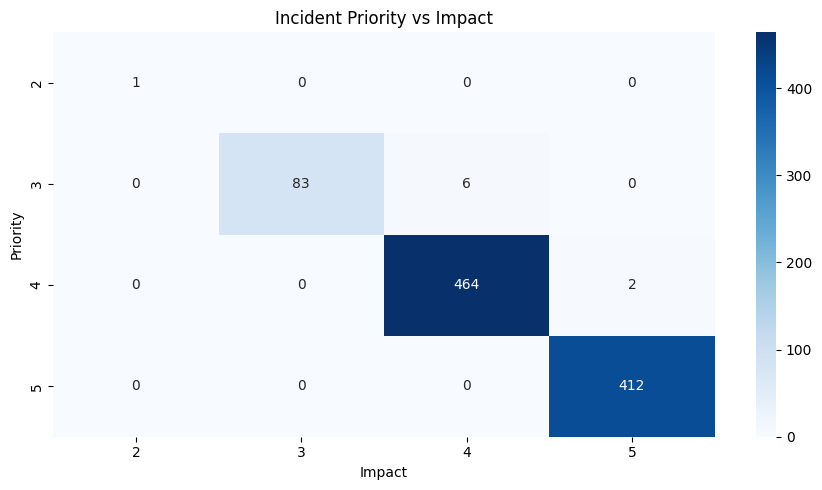

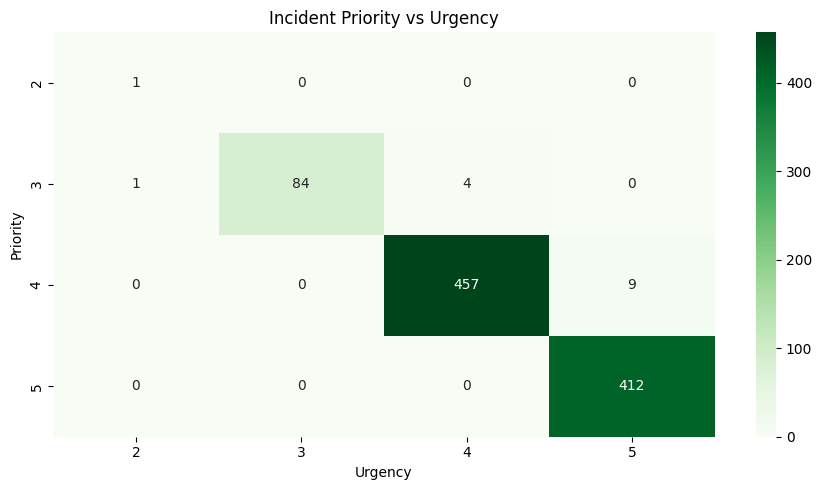

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a separate dataframe
priority_analysis_df = df_clean.copy()

# Clean categorical values
columns_to_analyze = ["Priority", "Impact", "Urgency"]

for col in columns_to_analyze:
    priority_analysis_df[col] = (priority_analysis_df[col].astype("string").str.strip())

# Priority vs Impact
print("Priority vs Impact:")
print(pd.crosstab(priority_analysis_df["Priority"],priority_analysis_df["Impact"],margins=True))

# Priority vs Urgency
print("\nPriority vs Urgency:")
print(pd.crosstab(priority_analysis_df["Priority"],priority_analysis_df["Urgency"],margins=True))

# Visualize Priority vs Impact
impact_table = pd.crosstab(priority_analysis_df["Priority"],priority_analysis_df["Impact"])

plt.figure(figsize=(9, 5))
sns.heatmap(impact_table, annot=True, fmt="d", cmap="Blues")
plt.title("Incident Priority vs Impact")
plt.xlabel("Impact")
plt.ylabel("Priority")
plt.tight_layout()
plt.show()

# Visualize Priority vs Urgency
urgency_table = pd.crosstab(priority_analysis_df["Priority"],priority_analysis_df["Urgency"])

plt.figure(figsize=(9, 5))
sns.heatmap(urgency_table, annot=True, fmt="d", cmap="Greens")
plt.title("Incident Priority vs Urgency")
plt.xlabel("Urgency")
plt.ylabel("Priority")
plt.tight_layout()
plt.show()

In [31]:
import pandas as pd
import numpy as np

# Create a separate dataframe
ml_df = df_clean.copy()

# Remove duplicate rows
before_rows = len(ml_df)
ml_df = ml_df.drop_duplicates()
after_rows = len(ml_df)

print("Rows before removing duplicates:", before_rows)
print("Duplicate rows removed:", before_rows - after_rows)
print("Rows after removing duplicates:", after_rows)

# Check target column
print("\nPriority value counts:")
print(ml_df["Priority"].value_counts(dropna=False))

# Check missing target values
print("\nMissing Priority values:",ml_df["Priority"].isna().sum())

# Display dataset information
print("\nDataset Information:")
print("Shape:", ml_df.shape)
print("\nColumn names:")
print(ml_df.columns.tolist())

# Display data types
print("\nData Types:")
print(ml_df.dtypes)

Rows before removing duplicates: 1000
Duplicate rows removed: 0
Rows after removing duplicates: 1000

Priority value counts:
Priority
4      466
5      412
3       89
NaN     32
2        1
Name: count, dtype: int64

Missing Priority values: 32

Dataset Information:
Shape: (1000, 25)

Column names:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'WBS', 'Incident_ID', 'Status', 'Impact', 'Urgency', 'Priority', 'number_cnt', 'Category', 'KB_number', 'Alert_Status', 'No_of_Reassignments', 'Open_Time', 'Reopen_Time', 'Resolved_Time', 'Close_Time', 'Handle_Time_hrs', 'Closure_Code', 'No_of_Related_Interactions', 'Related_Interaction', 'No_of_Related_Incidents', 'No_of_Related_Changes', 'Related_Change']

Data Types:
CI_Name                               object
CI_Cat                                object
CI_Subcat                             object
WBS                                   object
Incident_ID                           object
Status                                object
Impact                 

In [32]:
import pandas as pd
import numpy as np

# Work on the ML dataset
ml_df = ml_df.copy()

# Remove extra spaces from Priority values
ml_df["Priority"] = (ml_df["Priority"].astype("string").str.strip())

# Treat invalid placeholder values as missing
invalid_values = ["", "NA", "N/A", "NULL", "None", "nan"]

ml_df["Priority"] = ml_df["Priority"].replace(invalid_values, pd.NA)

# Display priority distribution before removing missing targets
print("Priority Distribution:")
print(ml_df["Priority"].value_counts(dropna=False))

# Remove rows without a valid target
before_count = len(ml_df)

ml_df = ml_df.dropna(subset=["Priority"]).copy()

after_count = len(ml_df)

print("\nRows before cleaning:", before_count)
print("Rows removed:", before_count - after_count)
print("Rows after cleaning:", after_count)

print("\nFinal Priority Classes:")
print(ml_df["Priority"].value_counts())

Priority Distribution:
Priority
4       466
5       412
3        89
<NA>     32
2         1
Name: count, dtype: Int64

Rows before cleaning: 1000
Rows removed: 32
Rows after cleaning: 968

Final Priority Classes:
Priority
4    466
5    412
3     89
2      1
Name: count, dtype: Int64


In [33]:
# Columns that may help predict incident priority
candidate_features = ["CI_Name","CI_Cat","CI_Subcat","Impact","Urgency","Category","No_of_Reassignments","No_of_Related_Interactions","No_of_Related_Incidents","No_of_Related_Changes"]

# Keep only columns available in the dataset
feature_columns = [col for col in candidate_features if col in ml_df.columns]

# Create feature dataset and target
X = ml_df[feature_columns].copy()
y = ml_df["Priority"].copy()

print("Selected Features:")
print(feature_columns)

print("\nFeature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nFeature Data Types:")
print(X.dtypes)

print("\nTarget Priority Distribution:")
print(y.value_counts())

Selected Features:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'Impact', 'Urgency', 'Category', 'No_of_Reassignments', 'No_of_Related_Interactions', 'No_of_Related_Incidents', 'No_of_Related_Changes']

Feature Dataset Shape: (968, 10)
Target Dataset Shape: (968,)

Feature Data Types:
CI_Name                       object
CI_Cat                        object
CI_Subcat                     object
Impact                        object
Urgency                       object
Category                      object
No_of_Reassignments           object
No_of_Related_Interactions    object
No_of_Related_Incidents       object
No_of_Related_Changes         object
dtype: object

Target Priority Distribution:
Priority
4    466
5    412
3     89
2      1
Name: count, dtype: Int64


In [34]:
import pandas as pd
import numpy as np

# Create a copy of the feature dataset
X = X.copy()

# Replace common missing-value placeholders
X = X.replace(["", "NA", "N/A", "NULL", "None", "nan"],np.nan)

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

# Display feature types
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

# Check missing values
print("\nMissing Values by Feature:")
print(X.isnull().sum())

print("\nTotal Missing Values:", X.isnull().sum().sum())

print("\nFeature Dataset Shape:", X.shape)

Numerical Features:
[]

Categorical Features:
['CI_Name', 'CI_Cat', 'CI_Subcat', 'Impact', 'Urgency', 'Category', 'No_of_Reassignments', 'No_of_Related_Interactions', 'No_of_Related_Incidents', 'No_of_Related_Changes']

Missing Values by Feature:
CI_Name                         0
CI_Cat                          4
CI_Subcat                       4
Impact                          0
Urgency                         0
Category                        0
No_of_Reassignments             0
No_of_Related_Interactions      1
No_of_Related_Incidents       926
No_of_Related_Changes         942
dtype: int64

Total Missing Values: 1877

Feature Dataset Shape: (968, 10)


In [35]:
from sklearn.model_selection import train_test_split

# Check Priority class counts
print("Priority Class Counts:")
print(y.value_counts())

# Remove classes having fewer than 2 records
class_counts = y.value_counts()
valid_classes = class_counts[class_counts >= 2].index

valid_indices = y[y.isin(valid_classes)].index

X = X.loc[valid_indices].copy()
y = y.loc[valid_indices].copy()

# Split features and target
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

# Display dataset sizes
print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Priority Distribution:")
print(y_train.value_counts())

print("\nTesting Priority Distribution:")
print(y_test.value_counts())

Priority Class Counts:
Priority
4    466
5    412
3     89
2      1
Name: count, dtype: Int64

Training Features Shape: (773, 10)
Testing Features Shape: (194, 10)

Training Target Shape: (773,)
Testing Target Shape: (194,)

Training Priority Distribution:
Priority
4    373
5    329
3     71
Name: count, dtype: Int64

Testing Priority Distribution:
Priority
4    93
5    83
3    18
Name: count, dtype: Int64


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[("num", numerical_transformer, numerical_features),("cat", categorical_transformer, categorical_features)])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing Completed Successfully!")
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Numerical Features: []
Categorical Features: ['CI_Name', 'CI_Cat', 'CI_Subcat', 'Impact', 'Urgency', 'Category', 'No_of_Reassignments', 'No_of_Related_Interactions', 'No_of_Related_Incidents', 'No_of_Related_Changes']

Preprocessing Completed Successfully!
Processed Training Shape: (773, 306)
Processed Testing Shape: (194, 306)


In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Model 1: Logistic Regression
logistic_model = LogisticRegression(max_iter=1000,class_weight="balanced",random_state=42)

logistic_model.fit(X_train_processed, y_train)

# Model 2: Random Forest
random_forest_model = RandomForestClassifier(n_estimators=100,class_weight="balanced",random_state=42,n_jobs=-1)

random_forest_model.fit(X_train_processed, y_train)

print("Both models trained successfully!")

# Generate predictions
logistic_predictions = logistic_model.predict(X_test_processed)
random_forest_predictions = random_forest_model.predict(X_test_processed)

print("\nModel training and prediction completed!")

Both models trained successfully!

Model training and prediction completed!


In [38]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report)

# Evaluate Logistic Regression
print("=" * 50)
print("LOGISTIC REGRESSION - EVALUATION")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test,logistic_predictions,zero_division=0))


# Evaluate Random Forest
print("\n" + "=" * 50)
print("RANDOM FOREST - EVALUATION")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_test, random_forest_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test,random_forest_predictions,zero_division=0))

LOGISTIC REGRESSION - EVALUATION
Accuracy: 0.9897

Classification Report:
              precision    recall  f1-score   support

           3       1.00      1.00      1.00        18
           4       1.00      0.98      0.99        93
           5       0.98      1.00      0.99        83

    accuracy                           0.99       194
   macro avg       0.99      0.99      0.99       194
weighted avg       0.99      0.99      0.99       194


RANDOM FOREST - EVALUATION
Accuracy: 0.9897

Classification Report:
              precision    recall  f1-score   support

           3       1.00      1.00      1.00        18
           4       1.00      0.98      0.99        93
           5       0.98      1.00      0.99        83

    accuracy                           0.99       194
   macro avg       0.99      0.99      0.99       194
weighted avg       0.99      0.99      0.99       194



In [39]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report)

# Evaluate Logistic Regression
print("=" * 50)
print("LOGISTIC REGRESSION - EVALUATION")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test,logistic_predictions,zero_division=0))


# Evaluate Random Forest
print("\n" + "=" * 50)
print("RANDOM FOREST - EVALUATION")
print("=" * 50)

print("Accuracy:", round(accuracy_score(y_test, random_forest_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test,random_forest_predictions,zero_division=0))

LOGISTIC REGRESSION - EVALUATION
Accuracy: 0.9897

Classification Report:
              precision    recall  f1-score   support

           3       1.00      1.00      1.00        18
           4       1.00      0.98      0.99        93
           5       0.98      1.00      0.99        83

    accuracy                           0.99       194
   macro avg       0.99      0.99      0.99       194
weighted avg       0.99      0.99      0.99       194


RANDOM FOREST - EVALUATION
Accuracy: 0.9897

Classification Report:
              precision    recall  f1-score   support

           3       1.00      1.00      1.00        18
           4       1.00      0.98      0.99        93
           5       0.98      1.00      0.99        83

    accuracy                           0.99       194
   macro avg       0.99      0.99      0.99       194
weighted avg       0.99      0.99      0.99       194



In [41]:
import pandas as pd

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score)

# Calculate Logistic Regression metrics
logistic_results = {"Model": "Logistic Regression","Accuracy": accuracy_score(y_test, logistic_predictions),
                    "Precision (Weighted)": precision_score(y_test, logistic_predictions,average="weighted", zero_division=0),
    "Recall (Weighted)": recall_score(y_test, logistic_predictions,average="weighted", zero_division=0),
    "F1-Score (Weighted)": f1_score(y_test, logistic_predictions,average="weighted", zero_division=0)}

# Calculate Random Forest metrics
rf_results = {"Model": "Random Forest","Accuracy": accuracy_score(y_test, random_forest_predictions),
              "Precision (Weighted)": precision_score(y_test, random_forest_predictions,average="weighted", zero_division=0),
    "Recall (Weighted)": recall_score(y_test, random_forest_predictions,average="weighted", zero_division=0),
    "F1-Score (Weighted)": f1_score(y_test, random_forest_predictions,average="weighted", zero_division=0)}

# Create comparison table
comparison_df = pd.DataFrame([logistic_results,rf_results])

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,0.9897,0.9899,0.9897,0.9897
1,Random Forest,0.9897,0.9899,0.9897,0.9897


In [42]:
# Select the model with the highest weighted F1-score
best_model_name = comparison_df.loc[comparison_df["F1-Score (Weighted)"].idxmax(),"Model"]

if best_model_name == "Logistic Regression":
    best_model = logistic_model
    best_predictions = logistic_predictions
else:
    best_model = random_forest_model
    best_predictions = random_forest_predictions

print("Best Model:", best_model_name)

print("Weighted F1-Score:",round(comparison_df.loc[comparison_df["Model"] == best_model_name,"F1-Score (Weighted)"].iloc[0],4))

Best Model: Logistic Regression
Weighted F1-Score: 0.9897


In [43]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate classification report
report = classification_report(y_test,best_predictions,output_dict=True,zero_division=0)

# Convert report into a DataFrame
priority_report = pd.DataFrame(report).transpose()

# Display precision, recall, and F1-score for each priority
print("Best Model:", best_model_name)
print("\nPriority-wise Performance:")

display(priority_report[["precision", "recall", "f1-score", "support"]].round(4))

Best Model: Logistic Regression

Priority-wise Performance:


,precision,recall,f1-score,support
3,1.0000,1.0000,1.0000,18.0000
4,1.0000,0.9785,0.9891,93.0000
5,0.9765,1.0000,0.9881,83.0000
accuracy,0.9897,0.9897,0.9897,0.9897
macro avg,0.9922,0.9928,0.9924,194.0000
weighted avg,0.9899,0.9897,0.9897,194.0000


In [44]:
import joblib
import os

# Create a folder to store the model
os.makedirs("/content/itsm_models", exist_ok=True)

# Save the best model
joblib.dump(best_model,"/content/itsm_models/best_itsm_priority_model.pkl")

# Save the preprocessing pipeline
joblib.dump(preprocessor,"/content/itsm_models/itsm_preprocessor.pkl")

print("Best model saved successfully!")
print("Model:", "/content/itsm_models/best_itsm_priority_model.pkl")
print("Preprocessor:", "/content/itsm_models/itsm_preprocessor.pkl")

Best model saved successfully!
Model: /content/itsm_models/best_itsm_priority_model.pkl
Preprocessor: /content/itsm_models/itsm_preprocessor.pkl


In [45]:
import joblib
import os

# Define saved model paths
model_path = "/content/itsm_models/best_itsm_priority_model.pkl"
preprocessor_path = "/content/itsm_models/itsm_preprocessor.pkl"

# Check whether files exist
print("Model file exists:", os.path.exists(model_path))
print("Preprocessor file exists:", os.path.exists(preprocessor_path))

# Load the saved model and preprocessor
loaded_model = joblib.load(model_path)
loaded_preprocessor = joblib.load(preprocessor_path)

print("\nModel loaded successfully!")
print("Selected Model:", best_model_name)

# Predict using the loaded model
sample_features = X_test.iloc[:5]

sample_processed = loaded_preprocessor.transform(sample_features)
sample_predictions = loaded_model.predict(sample_processed)

# Display predictions
prediction_results = pd.DataFrame({"Actual Priority": y_test.iloc[:5].values,"Predicted Priority": sample_predictions})

print("\nSample Prediction Results:")
display(prediction_results)

Model file exists: True
Preprocessor file exists: True

Model loaded successfully!
Selected Model: Logistic Regression

Sample Prediction Results:


,Actual Priority,Predicted Priority
0,4,4
1,4,4
2,4,4
3,4,4
4,4,4


In [46]:
import pandas as pd
import os

# Create prediction results DataFrame
prediction_results = pd.DataFrame({"Actual_Priority": y_test.iloc[:len(best_predictions)].values,"Predicted_Priority": best_predictions})

# Add prediction correctness
prediction_results["Prediction_Correct"] = (prediction_results["Actual_Priority"]== prediction_results["Predicted_Priority"])

# Create Results folder
os.makedirs("/content/Results", exist_ok=True)

# Save results to CSV
results_path = "/content/Results/itsm_priority_predictions.csv"

prediction_results.to_csv(results_path, index=False)

print("Prediction results saved successfully!")
print("File path:", results_path)

print("\nFirst 10 prediction results:")
display(prediction_results.head(10))

Prediction results saved successfully!
File path: /content/Results/itsm_priority_predictions.csv

First 10 prediction results:


,Actual_Priority,Predicted_Priority,Prediction_Correct
0,4,4,True
1,4,4,True
2,4,4,True
3,4,4,True
4,4,4,True
5,4,4,True
6,4,4,True
7,5,5,True
8,4,4,True
9,5,5,True


In [47]:
import pandas as pd
import os

# Calculate model performance
results_summary = pd.DataFrame({"Model": ["Logistic Regression","Random Forest"],
    "Accuracy": [accuracy_score(y_test, logistic_predictions),accuracy_score(y_test, random_forest_predictions)],
    "Weighted Precision": [precision_score(y_test, logistic_predictions,average="weighted", zero_division=0),
        precision_score(y_test, random_forest_predictions,average="weighted", zero_division=0)],
    "Weighted Recall": [recall_score(y_test, logistic_predictions,average="weighted", zero_division=0),
        recall_score(y_test, random_forest_predictions,average="weighted", zero_division=0)],
    "Weighted F1-Score": [f1_score(y_test, logistic_predictions,average="weighted", zero_division=0),
        f1_score(y_test, random_forest_predictions,average="weighted", zero_division=0)]})

# Create results folder
os.makedirs("/content/Results", exist_ok=True)

# Save summary
summary_path = "/content/Results/itsm_model_performance_summary.csv"
results_summary.to_csv(summary_path, index=False)

print("ITSM PROJECT - MODEL PERFORMANCE SUMMARY")
display(results_summary.round(4))

print("\nSelected Model:", best_model_name)
print("Summary saved to:", summary_path)

ITSM PROJECT - MODEL PERFORMANCE SUMMARY


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score
0,Logistic Regression,0.9897,0.9899,0.9897,0.9897
1,Random Forest,0.9897,0.9899,0.9897,0.9897



Selected Model: Logistic Regression
Summary saved to: /content/Results/itsm_model_performance_summary.csv


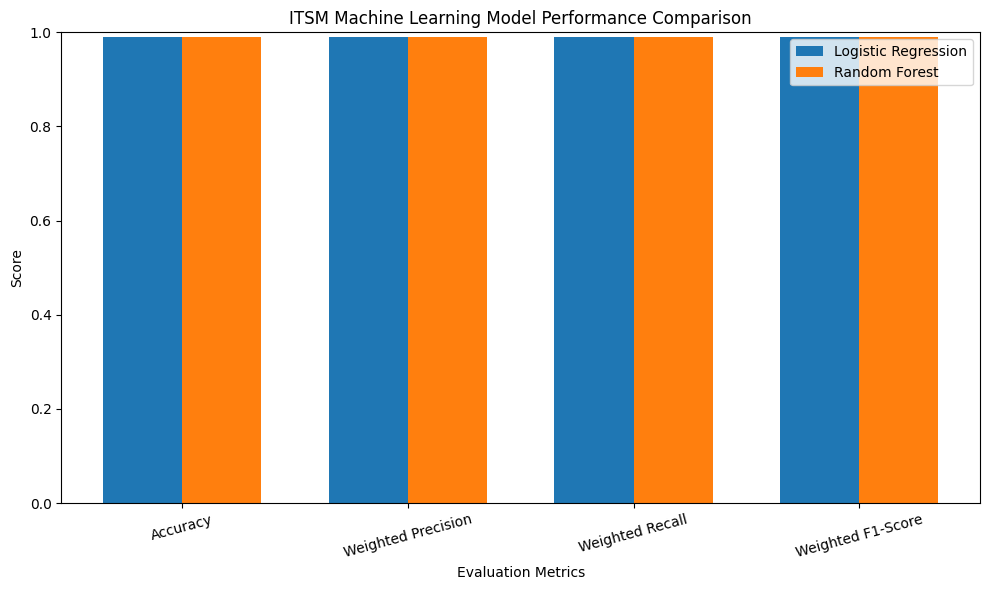

Performance comparison chart saved successfully!


In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare model comparison data
metrics = ["Accuracy","Weighted Precision","Weighted Recall","Weighted F1-Score"]

x = np.arange(len(metrics))
width = 0.35

logistic_scores = results_summary.iloc[0][metrics].astype(float).values
rf_scores = results_summary.iloc[1][metrics].astype(float).values

# Create comparison chart
plt.figure(figsize=(10, 6))

plt.bar(x - width / 2,logistic_scores,width,label="Logistic Regression")

plt.bar(x + width / 2,rf_scores,width,label="Random Forest")

plt.title("ITSM Machine Learning Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.xticks(x, metrics, rotation=15)
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

# Save chart
plt.savefig("/content/Results/itsm_model_performance_comparison.png",dpi=300,bbox_inches="tight")

plt.show()

print("Performance comparison chart saved successfully!")

FINAL INCIDENT PREDICTION ANALYSIS
----------------------------------------
Total Test Records: 194
Correct Predictions: 192
Incorrect Predictions: 2
Prediction Accuracy (%): 98.97


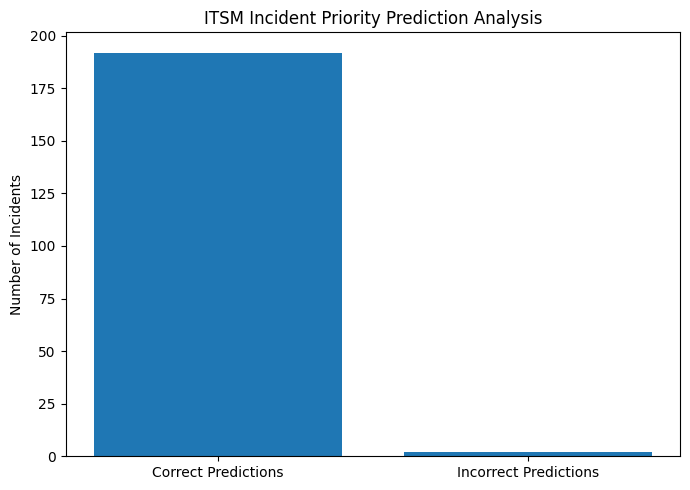

,Actual_Priority,Predicted_Priority,Correct_Prediction
0,4,4,True
1,4,4,True
2,4,4,True
3,4,4,True
4,4,4,True
5,4,4,True
6,4,4,True
7,5,5,True
8,4,4,True
9,5,5,True


In [49]:
import pandas as pd
import matplotlib.pyplot as plt

# Create final prediction DataFrame
final_predictions_df = pd.DataFrame({"Actual_Priority": y_test.values,"Predicted_Priority": best_predictions})

# Check prediction correctness
final_predictions_df["Correct_Prediction"] = (final_predictions_df["Actual_Priority"]== final_predictions_df["Predicted_Priority"])

# Calculate correct and incorrect predictions
correct_count = final_predictions_df["Correct_Prediction"].sum()
incorrect_count = (~final_predictions_df["Correct_Prediction"]).sum()

print("FINAL INCIDENT PREDICTION ANALYSIS")
print("-" * 40)

print("Total Test Records:", len(final_predictions_df))
print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", incorrect_count)

print("Prediction Accuracy (%):",round(final_predictions_df["Correct_Prediction"].mean() * 100,2))

# Plot correct vs incorrect predictions
plt.figure(figsize=(7, 5))

plt.bar(["Correct Predictions", "Incorrect Predictions"],[correct_count, incorrect_count])

plt.title("ITSM Incident Priority Prediction Analysis")
plt.ylabel("Number of Incidents")
plt.tight_layout()

plt.savefig("/content/Results/itsm_prediction_analysis.png",dpi=300,bbox_inches="tight")

plt.show()

# Display sample results
display(final_predictions_df.head(10))

In [50]:
import pandas as pd
import os

# Calculate model metrics
model_accuracy = accuracy_score(y_test, best_predictions)

model_precision = precision_score(y_test,best_predictions,average="weighted",zero_division=0)

model_recall = recall_score(y_test,best_predictions,average="weighted",zero_division=0)

model_f1 = f1_score(y_test,best_predictions,average="weighted",zero_division=0)

# Prepare findings
findings = ["ITSM incident priority prediction was developed using Machine Learning.",
    f"Selected model: {best_model_name}.",
    f"Test accuracy: {model_accuracy:.4f}.",
    f"Weighted precision: {model_precision:.4f}.",
    f"Weighted recall: {model_recall:.4f}.",
    f"Weighted F1-score: {model_f1:.4f}.",
    "Logistic Regression and Random Forest were evaluated.",
    "Confusion matrices were generated to analyze classification errors.",
    "Priority-wise recall should be reviewed to assess critical incident detection.",
    "The current analysis uses the records loaded into the notebook; full-dataset validation is recommended."]

# Display findings
print("FINAL PROJECT FINDINGS")
print("=" * 50)

for i, finding in enumerate(findings, start=1):
    print(f"{i}. {finding}")

# Save findings to a text file
os.makedirs("/content/Results", exist_ok=True)

findings_path = "/content/Results/itsm_project_findings.txt"

with open(findings_path, "w", encoding="utf-8") as file:
    file.write("ITSM INCIDENT MANAGEMENT USING MACHINE LEARNING\n\n")
    file.write("\n".join(findings))

print("\nFindings saved to:", findings_path)

FINAL PROJECT FINDINGS
1. ITSM incident priority prediction was developed using Machine Learning.
2. Selected model: Logistic Regression.
3. Test accuracy: 0.9897.
4. Weighted precision: 0.9899.
5. Weighted recall: 0.9897.
6. Weighted F1-score: 0.9897.
7. Logistic Regression and Random Forest were evaluated.
8. Confusion matrices were generated to analyze classification errors.
9. Priority-wise recall should be reviewed to assess critical incident detection.
10. The current analysis uses the records loaded into the notebook; full-dataset validation is recommended.

Findings saved to: /content/Results/itsm_project_findings.txt


In [51]:
import os

recommendations = ["1. Full Dataset Analysis:","Load and analyze the complete incident dataset instead of a limited sample.",

    "\n2. Critical Incident Detection:","Evaluate recall and F1-score specifically for P1 and P2 incidents.",

    "\n3. Model Improvement:","Experiment with hyperparameter tuning and compare additional classification algorithms.",

    "\n4. Feature Engineering:","Create useful features from incident timestamps, resolution duration, and reassignment history.",

    "\n5. Incident Volume Forecasting:","Use time-series forecasting to estimate future incident volumes.",

    "\n6. Automated Incident Categorization:","Explore models that recommend incident categories and support teams.",

    "\n7. Model Deployment:","Develop a web application that allows authorized users to enter incident details and receive priority predictions.",

    "\n8. Monitoring and Maintenance:","Monitor prediction quality over time and retrain the model when incident patterns change.",

    "\n9. Data Security:","Protect incident records and database credentials; do not expose confidential information in public repositories."]

print("PROJECT RECOMMENDATIONS")
print("=" * 50)

for item in recommendations:
    print(item)

# Save recommendations
os.makedirs("/content/Results", exist_ok=True)

recommendations_path = ("/content/Results/itsm_project_recommendations.txt")

with open(recommendations_path, "w", encoding="utf-8") as file:
    file.write("ITSM INCIDENT MANAGEMENT - RECOMMENDATIONS AND FUTURE IMPROVEMENTS\n\n")
    file.write("\n".join(recommendations))

print("\nRecommendations saved to:", recommendations_path)

PROJECT RECOMMENDATIONS
1. Full Dataset Analysis:
Load and analyze the complete incident dataset instead of a limited sample.

2. Critical Incident Detection:
Evaluate recall and F1-score specifically for P1 and P2 incidents.

3. Model Improvement:
Experiment with hyperparameter tuning and compare additional classification algorithms.

4. Feature Engineering:
Create useful features from incident timestamps, resolution duration, and reassignment history.

5. Incident Volume Forecasting:
Use time-series forecasting to estimate future incident volumes.

6. Automated Incident Categorization:
Explore models that recommend incident categories and support teams.

7. Model Deployment:
Develop a web application that allows authorized users to enter incident details and receive priority predictions.

8. Monitoring and Maintenance:
Monitor prediction quality over time and retrain the model when incident patterns change.

9. Data Security:
Protect incident records and database credentials; do not 

In [52]:
import os
import shutil

# Create project folder structure
project_path = "/content/ITSM_Incident_Management_Project"

folders = ["Models","Results","Reports"]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder),exist_ok=True)

# Copy trained model
shutil.copy2("/content/itsm_models/best_itsm_priority_model.pkl",os.path.join(project_path, "Models", "best_itsm_priority_model.pkl"))

# Copy preprocessing pipeline
shutil.copy2("/content/itsm_models/itsm_preprocessor.pkl",os.path.join(project_path, "Models", "itsm_preprocessor.pkl"))

# Copy result files if they exist
result_files = ["itsm_priority_predictions.csv","itsm_model_performance_summary.csv","itsm_model_performance_comparison.png","itsm_prediction_analysis.png","itsm_project_findings.txt","itsm_project_recommendations.txt"]

for filename in result_files:
    source = os.path.join("/content/Results", filename)

    if os.path.exists(source):
        shutil.copy2(source,os.path.join(project_path, "Results", filename))

print("Project folders organized successfully!")

# Display folder structure
for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for filename in files:
        print(f"{indent}    {filename}")

Project folders organized successfully!
ITSM_Incident_Management_Project/
    Models/
        best_itsm_priority_model.pkl
        itsm_preprocessor.pkl
    Results/
        itsm_project_recommendations.txt
        itsm_model_performance_comparison.png
        itsm_priority_predictions.csv
        itsm_project_findings.txt
        itsm_model_performance_summary.csv
        itsm_prediction_analysis.png
    Reports/


In [53]:
import shutil
import os
from IPython.display import display, FileLink

# Project folder
project_path = "/content/ITSM_Incident_Management_Project"

# ZIP file path
zip_path = "/content/ITSM_Incident_Management_Project"

# Create ZIP archive
shutil.make_archive(zip_path,"zip",root_dir="/content",base_dir="ITSM_Incident_Management_Project")

final_zip = zip_path + ".zip"

print("ZIP file created successfully!")
print("File size:", round(os.path.getsize(final_zip) / (1024 * 1024), 2), "MB")

# Display download link
display(FileLink(final_zip))

ZIP file created successfully!
File size: 0.18 MB


/content/ITSM_Incident_Management_Project.zip

In [54]:
import os

project_path = "/content/ITSM_Incident_Management_Project"
readme_path = os.path.join(project_path, "README.md")

readme_content = """
# ITSM Incident Management Using Machine Learning

## Project Overview
This project uses Machine Learning to predict IT incident priorities.
The goal is to help IT support teams identify and prioritize incidents
more efficiently.

## Objectives
- Analyze IT incident data.
- Perform data cleaning and exploratory data analysis.
- Predict incident priority using Machine Learning.
- Compare Logistic Regression and Random Forest models.
- Evaluate model performance using classification metrics.
- Save the trained model and prediction results.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SQLAlchemy
- MySQL
- Joblib

## Machine Learning Models
1. Logistic Regression
2. Random Forest Classifier

## Project Structure
- Models/: Saved Machine Learning model and preprocessor.
- Results/: Prediction results, performance metrics, charts,
  findings, and recommendations.
- Reports/: Project reports.

## Important Notes
The current notebook analysis uses the first 1,000 records retrieved
from the database. Results may change when the full dataset is analyzed.

Priority classes with fewer than two records were excluded from the
stratified train-test split.

## Future Improvements
- Analyze the complete dataset.
- Develop incident-volume forecasting.
- Explore automatic incident categorization.
- Develop an application for incident priority prediction.
- Evaluate additional Machine Learning models.

## Author
Rithick M
"""

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Location:", readme_path)

README.md created successfully!
Location: /content/ITSM_Incident_Management_Project/README.md


In [55]:
import os

project_path = "/content/ITSM_Incident_Management_Project"

print("ITSM Incident Management Project")
print("-" * 40)

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}  {file}")

print("\nProject file verification completed!")

ITSM Incident Management Project
----------------------------------------
ITSM_Incident_Management_Project/
  README.md
  Models/
    best_itsm_priority_model.pkl
    itsm_preprocessor.pkl
  Results/
    itsm_project_recommendations.txt
    itsm_model_performance_comparison.png
    itsm_priority_predictions.csv
    itsm_project_findings.txt
    itsm_model_performance_summary.csv
    itsm_prediction_analysis.png
  Reports/

Project file verification completed!


In [56]:
import os

project_path = "/content/ITSM_Incident_Management_Project"
reports_path = os.path.join(project_path, "Reports")

os.makedirs(reports_path, exist_ok=True)

report_content = """
# ITSM INCIDENT MANAGEMENT USING MACHINE LEARNING

## 1. Introduction
IT Service Management (ITSM) helps organizations manage IT incidents
and restore normal services efficiently. Machine Learning can help
support teams predict incident priorities and improve incident handling.

## 2. Project Objective
The main objective is to analyze IT incident data and build a Machine
Learning model that predicts incident priority based on available
incident information.

## 3. Dataset Description
The dataset contains IT incident information such as configuration item,
incident status, impact, urgency, category, priority, reassignment count,
and related incident information.

Note: The current notebook analysis uses the first 1,000 records
retrieved from the database. The findings should be validated using
the complete dataset.

## 4. Data Preprocessing
The preprocessing work includes:
- Handling missing and placeholder values.
- Removing exact duplicate records.
- Cleaning the target Priority column.
- Selecting relevant input features.
- Splitting the data into training and testing sets.
- Applying median imputation to numerical features.
- Applying most-frequent imputation and one-hot encoding to
  categorical features.

Priority classes with fewer than two records were excluded to enable
stratified train-test splitting.

## 5. Exploratory Data Analysis
The analysis includes:
- Priority distribution.
- Impact and urgency distribution.
- Incident status and category distribution.
- Missing-value analysis.
- Monthly incident counts based on Open_Time.
- Incident resolution time analysis.
- Reassignment and handling-time analysis.
- Relationships between priority, impact, and urgency.

## 6. Machine Learning Models
Two classification models were developed:
1. Logistic Regression
2. Random Forest Classifier

The models were evaluated using accuracy, weighted precision,
weighted recall, weighted F1-score, and confusion matrices.

The model with the higher weighted F1-score was selected as the
best-performing model in the notebook.

## 7. Results
The notebook generates model comparison metrics, actual-versus-predicted
priority results, confusion matrices, and prediction analysis charts.

Insert the actual evaluation values from the notebook before submitting
the final report. No performance values are assumed in this document.

## 8. Limitations
- The current analysis uses only the first 1,000 records.
- Rare priority classes may be excluded from model training.
- Performance on the full dataset has not yet been established.
- Incident-volume forecasting and automated application deployment
  are not included in the implemented classification workflow.

## 9. Future Enhancements
- Analyze the complete incident dataset.
- Develop incident-volume forecasting.
- Investigate automated incident categorization.
- Explore additional classification models.
- Develop a web application for incident priority prediction.
- Validate model performance on unseen operational data.

## 10. Conclusion
This project demonstrates a Machine Learning workflow for IT incident
priority classification, including data cleaning, exploratory analysis,
preprocessing, model training, evaluation, and result export.

Further validation using the complete dataset is recommended before
using the model in a real IT support environment.

## Author
Rithick M
"""

report_path = os.path.join(reports_path,"ITSM_Incident_Management_Project_Report.txt")

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report_content)

print("Project report created successfully!")
print("Saved at:", report_path)

from IPython.display import FileLink, display
display(FileLink(report_path))

Project report created successfully!
Saved at: /content/ITSM_Incident_Management_Project/Reports/ITSM_Incident_Management_Project_Report.txt


/content/ITSM_Incident_Management_Project/Reports/ITSM_Incident_Management_Project_Report.txt

In [57]:
import os
import shutil
from IPython.display import display, FileLink

# Main project folder
project_path = "/content/ITSM_Incident_Management_Project"

# Create required folders
os.makedirs(os.path.join(project_path, "Models"), exist_ok=True)
os.makedirs(os.path.join(project_path, "Results"), exist_ok=True)
os.makedirs(os.path.join(project_path, "Reports"), exist_ok=True)

# Check README
readme_path = os.path.join(project_path, "README.md")

if os.path.exists(readme_path):
    print("README.md: Available")
else:
    print("README.md: Not found")

# Check important folders
for folder in ["Models", "Results", "Reports"]:
    folder_path = os.path.join(project_path, folder)
    files = os.listdir(folder_path)
    print(f"\n{folder}: {len(files)} file(s)")
    for filename in files:
        print(" -", filename)

# Create ZIP
zip_path = "/content/ITSM_Incident_Management_Final"
shutil.make_archive(zip_path, "zip", root_dir=project_path)

final_zip = zip_path + ".zip"

print("\nFinal ZIP created successfully!")
print("File size:", round(os.path.getsize(final_zip) / (1024 * 1024), 2), "MB")

display(FileLink(final_zip))

README.md: Available

Models: 2 file(s)
 - best_itsm_priority_model.pkl
 - itsm_preprocessor.pkl

Results: 6 file(s)
 - itsm_project_recommendations.txt
 - itsm_model_performance_comparison.png
 - itsm_priority_predictions.csv
 - itsm_project_findings.txt
 - itsm_model_performance_summary.csv
 - itsm_prediction_analysis.png

Reports: 1 file(s)
 - ITSM_Incident_Management_Project_Report.txt

Final ZIP created successfully!
File size: 0.18 MB


/content/ITSM_Incident_Management_Final.zip

In [58]:
import os
import glob
import shutil
from IPython.display import display, FileLink

project_path = "/content/ITSM_Incident_Management_Project"

# Search for ITSM notebook files
notebooks = glob.glob("/content/*.ipynb")

print("Available notebook files:")
for notebook in notebooks:
    print(os.path.basename(notebook))

# Find the ITSM notebook
itsm_notebooks = [notebook for notebook in notebooks if "itsm" in os.path.basename(notebook).lower()]

if itsm_notebooks:
    notebook_path = itsm_notebooks[0]

    destination = os.path.join(project_path,"ITSM_Incident_Management_ML.ipynb")

    shutil.copy2(notebook_path, destination)

    print("\nNotebook copied successfully!")
    print("Saved at:", destination)
else:
    print("\nITSM notebook file was not found in /content.")
    print("Download your notebook from Colab first, then upload it to /content.")

Available notebook files:

ITSM notebook file was not found in /content.
Download your notebook from Colab first, then upload it to /content.


In [59]:
import os
import shutil
from IPython.display import display, FileLink

project_path = "/content/ITSM_Incident_Management_Project"

# Check project folder
if not os.path.exists(project_path):
    raise FileNotFoundError("Project folder not found. Run the previous steps first.")

# List all files before creating ZIP
print("PROJECT FILES")
print("=" * 40)

for root, dirs, files in os.walk(project_path):
    for filename in files:
        full_path = os.path.join(root, filename)
        print(os.path.relpath(full_path, project_path))

# Create final ZIP
zip_path = "/content/ITSM_Incident_Management_Final"

if os.path.exists(zip_path + ".zip"):
    os.remove(zip_path + ".zip")

shutil.make_archive(zip_path,"zip",root_dir="/content",base_dir="ITSM_Incident_Management_Project")

final_zip = zip_path + ".zip"

print("\nFinal ZIP created successfully!")
print("Size:", round(os.path.getsize(final_zip) / (1024 * 1024), 2), "MB")

display(FileLink(final_zip))

PROJECT FILES
README.md
Models/best_itsm_priority_model.pkl
Models/itsm_preprocessor.pkl
Results/itsm_project_recommendations.txt
Results/itsm_model_performance_comparison.png
Results/itsm_priority_predictions.csv
Results/itsm_project_findings.txt
Results/itsm_model_performance_summary.csv
Results/itsm_prediction_analysis.png
Reports/ITSM_Incident_Management_Project_Report.txt

Final ZIP created successfully!
Size: 0.18 MB


/content/ITSM_Incident_Management_Final.zip

In [60]:
import os

project_path = "/content/ITSM_Incident_Management_Project"

os.makedirs(project_path, exist_ok=True)

requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
sqlalchemy
pymysql
joblib
"""

requirements_path = os.path.join(project_path,"requirements.txt")

with open(requirements_path, "w", encoding="utf-8") as file:
    file.write(requirements)

print("requirements.txt created successfully!")
print("\nRequired libraries:")
print(requirements)

requirements.txt created successfully!

Required libraries:
pandas
numpy
matplotlib
seaborn
scikit-learn
sqlalchemy
pymysql
joblib



In [61]:
import os
import shutil
from IPython.display import display, FileLink

project_path = "/content/ITSM_Incident_Management_Project"

# Create updated ZIP
zip_path = "/content/ITSM_Incident_Management_Final"

if os.path.exists(zip_path + ".zip"):
    os.remove(zip_path + ".zip")

shutil.make_archive(zip_path,"zip",root_dir="/content",base_dir="ITSM_Incident_Management_Project")

final_zip = zip_path + ".zip"

print("Updated project ZIP created!")
print("File size:", round(os.path.getsize(final_zip) / (1024 * 1024), 2), "MB")

print("\nProject folder contents:")
for root, dirs, files in os.walk(project_path):
    for filename in files:
        print(os.path.relpath(os.path.join(root, filename), project_path))

print("\nClick below to download:")
display(FileLink(final_zip))

Updated project ZIP created!
File size: 0.18 MB

Project folder contents:
requirements.txt
README.md
Models/best_itsm_priority_model.pkl
Models/itsm_preprocessor.pkl
Results/itsm_project_recommendations.txt
Results/itsm_model_performance_comparison.png
Results/itsm_priority_predictions.csv
Results/itsm_project_findings.txt
Results/itsm_model_performance_summary.csv
Results/itsm_prediction_analysis.png
Reports/ITSM_Incident_Management_Project_Report.txt

Click below to download:


/content/ITSM_Incident_Management_Final.zip